### 🔹 Non-Linear Model – How to Know When Multiple Linear Regression (MLR) May Not Work

**Before Applying MLR — Clues from Data Exploration**

### 📌 Conceptual Clues:

**a. Pattern of Variables (Feature–Target Relationship)**
- If scatter plots suggest **non-linear relationships**, MLR may not work.
- **Example:**
  - Advertising: Spending more money doesn't always increase sales (diminishing returns).
  - Healthcare: Fast disease vs. slow — often shows a **threshold** or change point.
- **Visual Tip:** Scatter plots turn a **curve**, not a straight direction.

**b. Correlation Doesn't Tell the Whole Story**
- Low or near-zero Pearson correlation but visible non-linear pattern.
- MLR will suggest **no relationship** in these situations.
- **Visual Tip:** Look for **clusters** or **curved pattern** in scatter plot — support non-linearity.


### 🔹 Before Applying MLR — Clues from Data Exploration

### 📌 Conceptual Clues:

**a. Pattern of Variables (Feature–Target Relationship)**
- If the real-world scenario is **non-linear** (e.g., a straight-line effect).
- **Examples:**
  - Marketing: Higher advertising spend doesn't always linearly increase sales (diminishing returns).
  - Healthcare: Fast disease vs. slow — often shows a **U-shape**.
- **Visual Tip:** Scatter plots turn a **curve**, bend, or change direction.


### 🔹 b. Correlation Doesn't Tell the Whole Story

- Low or near-zero **Pearson correlation** but visible non-linear pattern.
- MLR will suggest **no relationship** in these situations.
- **Visual Tip:** Weak correlation but clear pattern in scatter plot → suspect **non-linearity**.


### 🔹 c. Interaction Effects Present

- The impact of one feature **depends on the level of another** feature.
- MLR (without added terms) misses these combined effects.
- **Example:** Sales success depends on both **TV** and **Radio** together — not just independently.
- **MLR Limitation:** MLR cannot capture these unless you **manually add interaction terms**.


### 🔹 d. Forced Feature Engineering

- Patterns (like **U-shapes** or **step functions**) — MLR cannot capture these unless you **manually add nonlinear features**.
- **Action:** Time to explore **non-linear methods** that naturally capture patterns.


### 🔹 Summary Table: When to Consider Non-linear Models

| Scenario | What to Consider |
|---|---|
| Curved patterns in scatter plots | Polynomial Regression, GAMs |
| Weak correlation — visible pattern | Decision Trees, Random Forest |
| Effects depend on feature combinations | Decision Trees, Gradient Boosting |
| Performance drops when adding new terms | Non-linear regression, ensemble methods |


### 🔹 Key Takeaways

- "Linear regression is strong, but real-world relationships are often curved, layered, or conditional. Before you go non-linear, explore the data carefully — and when the line starts to break, don't force it — explore non-linear models."


# Linear vs Non-Linear Regression Demonstration Using Advertising Data

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_squared_error , r2_score
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures # offers Non-Linearity
from sklearn.model_selection import train_test_split

In [2]:
# Step 2: load the Dataset
data = pd.read_csv('advertising_nonlinear.csv')

In [4]:
data.head()

,TV,Radio,Newspaper,Sales,Sales_Nonlinear
0,230.1,37.8,69.2,22.1,5.35
1,44.5,39.3,45.1,10.4,7.20
2,17.2,45.9,69.3,12.0,7.77
3,151.5,41.3,58.5,16.5,9.82
4,180.8,10.8,58.4,17.9,5.66


In [5]:
data.shape

(32, 5)

In [11]:
# Step 3: Select Features and Target
x = data[['TV','Radio']]  #Newspaper has no much impact we saw earlier
y_linear = data['Sales_Nonlinear']

In [10]:
x.head()

,TV,Radio
0,230.1,37.8
1,44.5,39.3
2,17.2,45.9
3,151.5,41.3
4,180.8,10.8


In [12]:
y_linear.head()

0    5.35
1    7.20
2    7.77
3    9.82
4    5.66
Name: Sales_Nonlinear, dtype: float64

In [14]:
# Step 4: Split the Data
x_train, x_test, y_train, y_test = train_test_split(x,y_linear, test_size = 0.2, random_state = 42)

In [15]:
# Quiz can you write here code to check size of eaach variable after split

In [17]:
# Step 5: Apply Linear Regression
lin_reg = LinearRegression()
lin_reg.fit(x_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [19]:
# Predict
y_pred_linear = lin_reg.predict(x_test)

In [20]:
# Evaluate linear Model
r2_lin = r2_score(y_test, y_pred_linear)
rmse_lin = np.sqrt(mean_squared_error(y_test, y_pred_linear))

print("Linear Regression R² : ", round(r2_lin, 3))
print("Linear Regression RMSE : ", round(rmse_lin, 3))

Linear Regression R² :  0.269
Linear Regression RMSE :  2.144


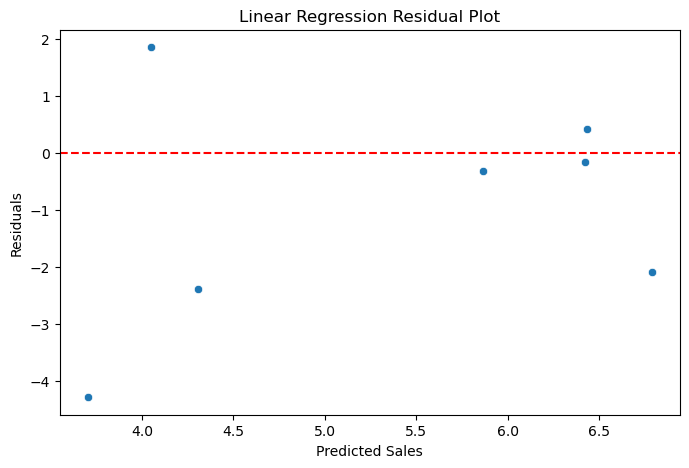

In [21]:
# Plot Residuals for Linear Regression
residuals_lin = y_test - y_pred_linear
plt.figure(figsize = (8,5))
sns.scatterplot(x=y_pred_linear, y = residuals_lin)
plt.axhline(0,color = 'red', linestyle = '--')
plt.title('Linear Regression Residual Plot')
plt.xlabel('Predicted Sales')
plt.ylabel('Residuals')
plt.show()

In [22]:
# Step 6: Apply Polynomial Regression (Degree 2)

In [29]:
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=2, include_bias=False)

x_poly_train = poly.fit_transform(x_train)
x_poly_test = poly.transform(x_test)


# 🔹 Transforming Features Into a Better Fit

#- **"This transforms features into [x1, x1², x1·x2, ...] for better model flexibility.**
#- **For a first simple [2, 3]:**
#- **Original: [2, 3] →**
#- **Transformed becomes:**
#- **f([2, 3]) → [2, 4, 6, 9] → e.g., [2, 4, 6, 9]** → x₁, x₁², x₁x₂, x₂²

### 🔹 Second Example of Feature Transformation

#- **For second sample [1, 4]:**
#- **Original: [1, 4] → [1·1, 4·4]**
#- **Transformed becomes:**
#- **f: [1, 4] → [1, 1, 4, 16], x₁²+x₂, x₁·x₂=4, x₂²=16**
#- **This allows linear regression to model relationships (like curves)** using the expanded feature set.

### 🔹 The Transformed Model Equation

#- **y = w₀ + w₁x₁ + w₂x₂ + w₃x₁² + w₄x₁x₂ + w₅x₂²**
#- **Which can capture curved patterns and feature interactions** — the model stays linear in the weights, but the expanded features let it fit curves and interactions.


In [30]:
poly_reg = LinearRegression()
poly_reg.fit(x_poly_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [33]:
# Predict
y_pred_poly = poly_reg.predict(x_poly_test)

In [34]:
# Evaluate Polynomial Model
r2_poly = r2_score(y_test, y_pred_poly)
rmse_poly = np.sqrt(mean_squared_error(y_test, y_pred_poly))

print("Linear Regression R² : ", round(r2_poly, 3))
print("Linear Regression RMSE : ", round(rmse_poly, 3))

Linear Regression R² :  0.895
Linear Regression RMSE :  0.811


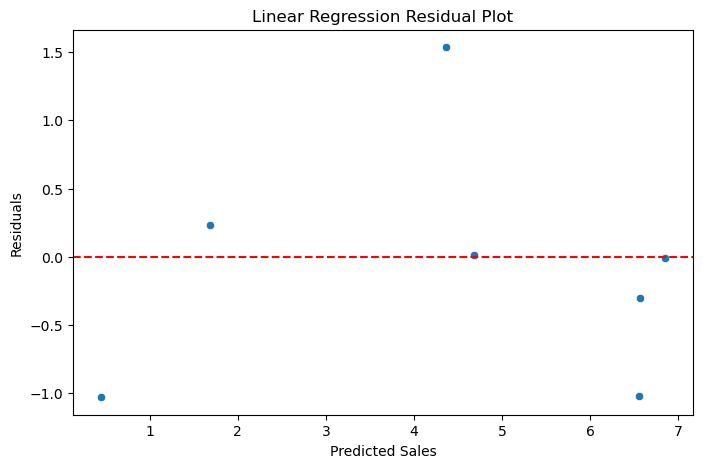

In [35]:
# Plot Residuals for Polynomial Regression
residuals_poly = y_test - y_pred_poly
plt.figure(figsize = (8,5))
sns.scatterplot(x=y_pred_poly, y = residuals_poly)
plt.axhline(0,color = 'red', linestyle = '--')
plt.title('Linear Regression Residual Plot')
plt.xlabel('Predicted Sales')
plt.ylabel('Residuals')
plt.show()

In [38]:
#Range is smaller (±1.0 vs. ±4.0 in the linear plot), meaning better accuracy.

In [39]:
# Step 7: Conclusion Summary

print("\nModel Comparison:")
print(f"Linear Regression → R²: {round(r2_lin, 3)}, RMSE: {round(rmse_lin, 3)}")
print(f"Polynomial Regression → R²: {round(r2_poly, 3)}, RMSE: {round(rmse_poly, 3)}")


Model Comparison:
Linear Regression → R²: 0.269, RMSE: 2.144
Polynomial Regression → R²: 0.895, RMSE: 0.811


In [41]:
# Key Insight:
# If the Polynomial Regression shows higher R² and 1
# Lower MSE and more random residuals,
# it indicates a better fit for nonlinear data.